# CICIDS2017 - Full Multiclass Pipeline
This notebook loads all 5 CSV files from the improved CICIDS2017 dataset, drops duplicates across the entire dataset to prevent data leakage, downsamples the majority BENIGN class, and trains a Multiclass XGBoost model to classify the exact attack type.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

plt.style.use('dark_background')
sns.set_palette('muted')

## 1. Load All 5 CSV Files
We concatenate the entire 7-day dataset into a single massive DataFrame.

In [10]:
dataset_dir = r'D:\Infosys\2017_improved'
all_files = glob.glob(os.path.join(dataset_dir, '*.csv'))

df_list = []
for file in all_files:
    print(f'Loading {os.path.basename(file)}...')
    temp_df = pd.read_csv(file)
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
print(f'\nTotal combined shape: {df.shape}')

Loading friday.csv...
Loading monday.csv...
Loading thursday.csv...
Loading tuesday.csv...
Loading wednesday.csv...

Total combined shape: (2099976, 91)


## 2. Drop Duplicates (Preventing Data Leakage)
As noted by security SMEs, flow datasets often have identical rows (especially during flood attacks). If these are split between train and test, the model memorizes them and reports 1.000 accuracy. We must drop them first.

In [11]:
# Drop columns that could cause overfitting to specific network architecture rather than attack behavior
cols_to_drop = ['_id', 'timestamp', 'source_ip', 'destination_ip', 'flow_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns], errors='ignore')

# Clean invalid data
df = df.replace([np.inf, -np.inf], np.nan).dropna()

initial_rows = len(df)
df = df.drop_duplicates()
dropped = initial_rows - len(df)
print(f'Dropped {dropped} duplicate rows ({(dropped/initial_rows)*100:.2f}% of dataset).\nNew shape: {df.shape}')

Dropped 4 duplicate rows (0.00% of dataset).
New shape: (2099967, 84)


## 3. Downsample Majority Class & Label Encoding
We keep 100% of the attack traffic, but downsample BENIGN to a reasonable maximum so the model isn't heavily biased toward guessing BENIGN.

In [12]:
df_balanced = pd.concat([df_benign, df_attack]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f'\nBalanced dataset shape: {df_balanced.shape}')

# Merge ALL sparse subclasses (including Web Attacks) into their parent classes
df_balanced['label'] = df_balanced['label'].replace({
    'Infiltration - Attempted': 'Infiltration',
    'Infiltration - Portscan': 'Infiltration',
    'FTP-Patator - Attempted': 'FTP-Patator',
    'SSH-Patator - Attempted': 'SSH-Patator',
    'DoS GoldenEye - Attempted': 'DoS GoldenEye',
    'DoS Hulk - Attempted': 'DoS Hulk',
    'DoS Slowhttptest - Attempted': 'DoS Slowhttptest',
    'DoS Slowloris - Attempted': 'DoS Slowloris',
    'Botnet - Attempted': 'Botnet',
    'Web Attack - Brute Force': 'Web Attack',
    'Web Attack - Brute Force - Attempted': 'Web Attack',
    'Web Attack - SQL Injection': 'Web Attack',
    'Web Attack - SQL Injection - Attempted': 'Web Attack',
    'Web Attack - XSS': 'Web Attack',
    'Web Attack - XSS - Attempted': 'Web Attack'
})

# Label Encoding for Multiclass
le = LabelEncoder()
y = le.fit_transform(df_balanced['label'])

# Ensure features are numeric
X = df_balanced.select_dtypes(include=[np.number]).fillna(0)


Balanced dataset shape: (717410, 84)


## 4. Train/Test Split (Stratified)
We stratify by `y` so that rare attack types (like Infiltration) appear in both the training and testing sets.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training Multiclass Model on {X_train.shape[0]} rows and {X_train.shape[1]} features...')

Training Multiclass Model on 573928 rows and 83 features...


In [14]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import RandomOverSampler

print("Applying RandomOverSampler to duplicate rare minority classes (like Infiltration)...")
# RandomOverSampler instantly duplicates minority samples so they are just as large as majority classes.
# This forces the model to heavily penalize missing even a single Infiltration sample.
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train_scaled, y_train)

print("Training Random Forest on oversampled data...")
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)

model.fit(X_train_resampled, y_train_resampled)

print("Predicting...")
y_pred = model.predict(X_test_scaled)
print("Done!")

Applying RandomOverSampler to duplicate rare minority classes (like Infiltration)...
Training Random Forest on oversampled data...
Predicting...
Done!


## 5. Evaluation & Export

Overall Accuracy: 0.9914

                  precision    recall  f1-score   support

          BENIGN       1.00      1.00      1.00     40000
          Botnet       1.00      1.00      1.00       961
            DDoS       1.00      1.00      1.00     19029
   DoS GoldenEye       1.00      1.00      1.00      1529
        DoS Hulk       1.00      1.00      1.00     31810
DoS Slowhttptest       1.00      1.00      1.00      1022
   DoS Slowloris       1.00      1.00      1.00      1141
     FTP-Patator       1.00      1.00      1.00       797
      Heartbleed       1.00      1.00      1.00         2
    Infiltration       0.96      0.96      0.96     14369
        Portscan       0.98      0.98      0.98     31813
     SSH-Patator       1.00      1.00      1.00       598
      Web Attack       1.00      0.99      0.99       411

        accuracy                           0.99    143482
       macro avg       0.99      0.99      0.99    143482
    weighted avg       0.99      0.99      0

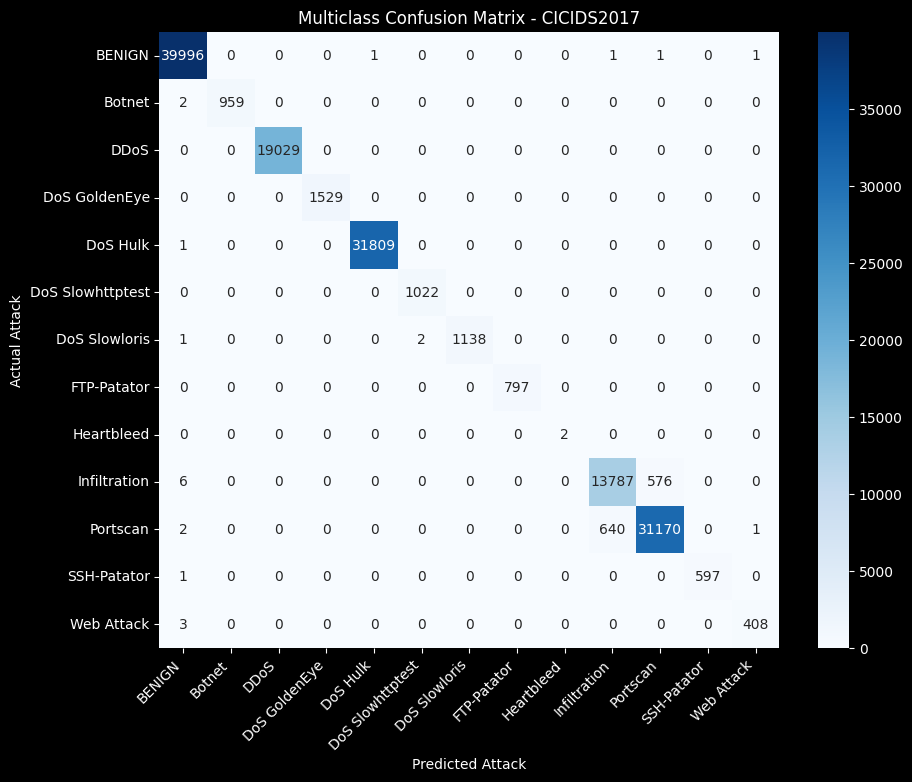

In [15]:
print(f'Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}\n')

# Classification Report breaks down metrics per-attack-type
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Multiclass Confusion Matrix - CICIDS2017')
plt.ylabel('Actual Attack')
plt.xlabel('Predicted Attack')
plt.xticks(rotation=45, ha='right')
plt.show()

In [16]:
# Export the Pipeline Components
os.makedirs(r'd:\Infosys\backend\ml\saved_models', exist_ok=True)

joblib.dump(model, r'd:\Infosys\backend\ml\saved_models\xgboost_multiclass.pkl')
joblib.dump(scaler, r'd:\Infosys\backend\ml\saved_models\scaler_multiclass.pkl')
joblib.dump(le, r'd:\Infosys\backend\ml\saved_models\label_encoder.pkl')

print('Multiclass Model, Scaler, and Label Encoder saved successfully!')

Multiclass Model, Scaler, and Label Encoder saved successfully!


## 6. The Ultimate Model Showdown
Compare multiple top-tier ML algorithms side-by-side to find the ultimate champion for the project!

In [17]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
import time
import pandas as pd

print("Initializing the Ultimate Model Showdown...")
models = {
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1, n_jobs=-1, random_state=42)
}

results = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    start_time = time.time()
    
    # Train
    model.fit(X_train_resampled if name == 'XGBoost' else X_train_scaled, 
              y_train_resampled if name == 'XGBoost' else y_train)
              
    train_time = time.time() - start_time
    
    # Predict
    print(f"Evaluating {name}...")
    y_pred_m = model.predict(X_test_scaled)
    
    # Calculate Macro F1 (gives equal weight to minority classes)
    macro_f1 = f1_score(y_test, y_pred_m, average='macro')
    # Calculate Weighted F1
    weighted_f1 = f1_score(y_test, y_pred_m, average='weighted')
    
    results.append({
        "Model": name,
        "Macro F1 (Minority Focus)": round(macro_f1, 4),
        "Weighted F1 (Overall)": round(weighted_f1, 4),
        "Training Time (s)": round(train_time, 2)
    })

print("\n" + "="*50)
print("🏆 ULTIMATE MODEL SHOWDOWN RESULTS 🏆")
print("="*50)
results_df = pd.DataFrame(results).sort_values(by="Macro F1 (Minority Focus)", ascending=False)
display(results_df)

Initializing the Ultimate Model Showdown...

Training Decision Tree...
Evaluating Decision Tree...

Training Random Forest...
Evaluating Random Forest...

Training Extra Trees...
Evaluating Extra Trees...

Training XGBoost...
Evaluating XGBoost...

🏆 ULTIMATE MODEL SHOWDOWN RESULTS 🏆


,Model,Macro F1 (Minority Focus),Weighted F1 (Overall),Training Time (s)
3,XGBoost,0.9948,0.9915,153.36
1,Random Forest,0.9947,0.9917,33.09
2,Extra Trees,0.9935,0.9892,30.67
0,Decision Tree,0.9927,0.9889,26.10
